In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import CoxPHFitter

plt.rcParams["font.family"] = "Arial Unicode MS"
pd.set_option("display.width", 200)

df = pd.read_csv("../data/processed/survival_2015.csv")

# ===== 1. 資本額：取 log10 =====

In [2]:
df = df[df["capital"] > 0].copy()
df["log_capital"] = np.log10(df["capital"])

# ===== 2. 縣市：前 6 大保留，其他合併 =====


In [5]:
top_counties = df["county"].value_counts().index[:6]
df["county_group"] = df["county"].where(df["county"].isin(top_counties), "其他縣市")


# ===== 3. 把縣市轉成虛擬變數，以臺北市為對照組 =====


In [4]:
dummies = pd.get_dummies(df["county_group"], dtype=int)
dummies = dummies.drop(columns=["臺北市"])

# ===== 4. 組合模型資料並跑 Cox =====


In [7]:
model_df = pd.concat(
    [df[["duration_months", "event", "log_capital"]], dummies],
    axis=1,
)

cph = CoxPHFitter()
cph.fit(model_df, duration_col="duration_months", event_col="event")



<lifelines.CoxPHFitter: fitted with 43632 total observations, 28773 right-censored observations>

# ===== 5. 看結果 =====


In [8]:
result = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]]
print(result.round(3))
print()
print("C-index：", round(cph.concordance_index_, 3))

             exp(coef)  exp(coef) lower 95%  exp(coef) upper 95%      p
covariate                                                              
log_capital      0.749                0.730                0.768  0.000
其他縣市             0.796                0.756                0.838  0.000
新北市              0.904                0.862                0.949  0.000
桃園市              0.913                0.859                0.971  0.004
臺中市              0.863                0.820                0.908  0.000
臺南市              0.782                0.723                0.846  0.000
高雄市              0.783                0.737                0.832  0.000

C-index： 0.561


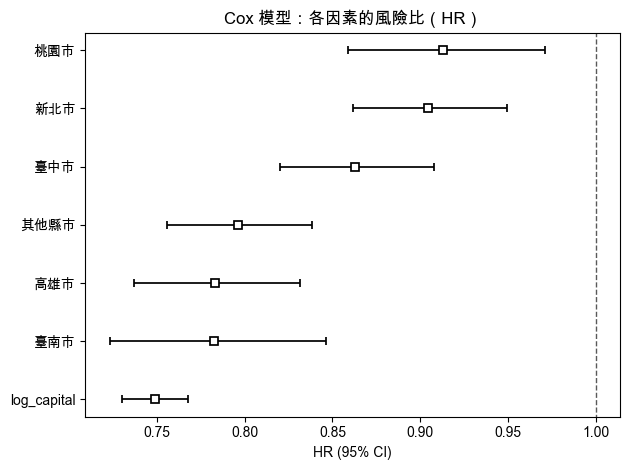

In [12]:
cph.plot(hazard_ratios=True)
plt.title("Cox 模型：各因素的風險比（HR）")
plt.tight_layout()
plt.savefig("../reports/figures/cox_forest.png", dpi=150)
plt.show()